# Лабораторная работа 1. Задача классификации

**Цель работы:** реализовать алгоритмы бинарной классификации «с нуля» на NumPy, применить их к реальному датасету и сравнить с эталонными реализациями из scikit-learn.

**Как работать с ноутбуком**

- В ячейке конфигурации (раздел 1) укажите номер задачи (зависит от группы) и номер варианта (зависит от списка).
- Ячейки с `raise NotImplementedError` или `# TODO` — ваша работа. Остальные ячейки менять не нужно.
- Алгоритмы пишутся **только на NumPy**. Pandas — для загрузки и подготовки данных, matplotlib/seaborn — для графиков. scikit-learn разрешён только в ячейках проверки и в сравнении с эталоном.
- После каждого блока стоит тест. Не переходите дальше, пока он не пройден.
- Работа принимается, если выполнены критерии из раздела 10 (качество не ниже заданного порога и не хуже эталона sklearn).
- Разрабатывайте на подвыборке (`USE_FULL_DATA = False`), финальный прогон делайте на полных данных.
- Циклов по объектам выборки в `predict` и в основных вычислениях быть не должно: используйте векторизацию.

**Задания**

1. Проанализировать датасет, привести его к числовому виду, построить корреляционную матрицу, предложить способы расширения данных.
2. Реализовать метрики качества и два классификатора: метод вашего варианта и нейронную сеть прямого распространения (MLP).
3. Подобрать гиперпараметры, обосновать выбор.
4. Оценить качество на тестовой выборке, сравнить с scikit-learn, проанализировать ошибочно классифицированные объекты.
5. Улучшить результат (обработка данных, порог, баланс классов, параметры) и сделать выводы.

**Задачи (датасеты)**

| № | Задача | Источник |
|---|--------|----------|
| 1 | Сердечно-сосудистые заболевания | [Kaggle](https://www.kaggle.com/datasets/kamilpytlak/personal-key-indicators-of-heart-disease) |
| 2 | Качество воды | [Kaggle](https://www.kaggle.com/datasets/adityakadiwal/water-potability) |
| 3 | Стартапы | [Kaggle](https://www.kaggle.com/datasets/manishkc06/startup-success-prediction) |
| 4 | Задержка рейса | [Kaggle](https://www.kaggle.com/datasets/threnjen/2019-airline-delays-and-cancellations) |
| 5 | Вредоносные сайты | [Kaggle](https://www.kaggle.com/xwolf12/malicious-and-benign-websites) |

**Варианты**

| № варианта | Метод вашего варианта | Вторая модель |
|---|---|---|
| 1 | Наивный байесовский классификатор (гауссов) | MLP |
| 2 | Метод опорных векторов (линейный) | MLP |
| 3 | Решающее дерево | MLP |
| 4 | k ближайших соседей | MLP |
| 5 | Случайный лес (нужно реализовать и решающее дерево) — **для самостоятельного разбора** | MLP |
| 6 | Логистическая регрессия — **для самостоятельного разбора** | MLP |

Методы вариантов 5 и 6 не разбирались на занятиях: теорию изучите самостоятельно по учебным материалам.

### 1. Подготовка окружения

#### 1.1. Импорт библиотек

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
pd.set_option("display.max_columns", 50)

#### 1.2. Конфигурация

Укажите **свои** `TASK` и `VARIANT`. Имена файлов и целевых колонок заданы в словаре `TASKS`: сверьте их с файлами, которые вы скачали, и при необходимости поправьте.

In [2]:
TASK = 2
VARIANT = 3

SEED = 42
DATA_DIR = "data"
USE_FULL_DATA = False
DEV_N = 20_000

TASKS = {
    1: dict(name="Сердечно-сосудистые заболевания", file="heart_2020_cleaned.csv", target="HeartDisease", positive="Yes"),
    2: dict(name="Качество воды", file="water_potability.csv", target="Potability", positive=1),
    3: dict(name="Стартапы", file="startup data.csv", target="status", positive="acquired"),
    4: dict(name="Задержка рейса", file="full_data.csv", target="DEP_DEL15", positive=1),
    5: dict(name="Вредоносные сайты", file="dataset.csv", target="Type", positive=1),
}
MIN_AUC = {1: 0.8, 2: 0.65, 3: 0.70, 4: 0.60, 5: 0.85}
ACC_TOL = 0.07
METHODS = {1: "nb", 2: "svm", 3: "dt", 4: "knn", 5: "rf", 6: "logreg"}
METHOD_NAMES = {
    "rf": "Случайный лес", "svm": "SVM", "logreg": "Логистическая регрессия",
    "knn": "kNN", "nb": "Наивный Байес", "dt": "Решающее дерево",
}

cfg = TASKS[TASK]
METHOD = METHODS[VARIANT]
print(f"Задача {TASK}: {cfg['name']}")
print(f"Вариант {VARIANT}: {METHOD_NAMES[METHOD]} + MLP")


def is_mine(*keys):
    if METHOD in keys:
        return True
    print(f"Пропуск: не ваш вариант (ваш метод — {METHOD_NAMES[METHOD]})")
    return False

Задача 2: Качество воды
Вариант 3: Решающее дерево + MLP


#### 1.3. Служебные функции

Готовые функции для разбиения выборки и стандартизации. Они понадобятся дальше, менять их не нужно.

In [3]:
def train_test_split_np(X, y, test_size=0.2, seed=SEED, stratify=True):
    r = np.random.default_rng(seed)
    n = len(y)
    if stratify:
        parts = []
        for c in np.unique(y):
            idx = np.flatnonzero(y == c)
            r.shuffle(idx)
            parts.append(idx[: int(round(len(idx) * test_size))])
        test_idx = np.concatenate(parts)
    else:
        test_idx = r.permutation(n)[: int(round(n * test_size))]
    mask = np.zeros(n, dtype=bool)
    mask[test_idx] = True
    return X[~mask], X[mask], y[~mask], y[mask]


def subsample(X, y, n, seed=SEED):
    if len(y) <= n:
        return X, y
    idx = np.random.default_rng(seed).choice(len(y), size=n, replace=False)
    return X[idx], y[idx]


class Standardizer:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


class BaseClassifier:
    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

### 2. Анализ и подготовка данных (задание 1)

#### 2.1. Загрузка

In [4]:
df = pd.read_csv(f"{DATA_DIR}/{cfg['file']}")
print(df.shape)
df.head()

(3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


#### 2.2. Описание датасета

Выведите размер датасета, список колонок и их типы, число пропусков, статистики (`describe`) и распределение целевой переменной. Ниже в markdown-ячейке опишите, что вы увидели: какие колонки что означают, есть ли пропуски, выбросы, дисбаланс классов.

In [5]:
# TODO: размер, колонки, типы, пропуски, describe(), распределение целевой переменной

print("размер:")
print(df.shape)
print("колонки:")
print(df.columns.tolist())
print("типы:")
print(df.dtypes)
print("пропуски:")
print(df.isnull().sum())
print((df.isnull().sum() / len(df)) * 100)
print("дескрайб(описание дс):")
print(df.describe())
print("распределение целевой переменной")
print(df.value_counts())
print(df.value_counts(normalize=True))

размер:
(3276, 10)
колонки:
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']
типы:
ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object
пропуски:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64
ph                 14.987790
Hardness            0.000000
Solids              0.000000
Chloramines         0.000000
Sulfate            23.840049
Conductivity        0.000000
Organic_carbon      0.000000
Trihalomethanes     4.945055
Turbidity           0.000000
Potability          0.000000
dtyp

**Описание датасета:** Датасет содержит 3276 объектов и 10 колонок (9 признаков + целевая).
Типы: все признаки числовые (float), целевая переменная Potability — бинарная (0 или 1).
Пропуски: присутствуют в признаках ph, Sulfate, Trihalomethanes. Их необходимо заполнить.
Дисбаланс классов: класс 0 (непитьевая вода) составляет ~61%, класс 1 (питьевая) ~39%. Дисбаланс умеренный, но требует внимания при выборе метрик.
Выбросы: признаки Solids и Chloramines имеют сильный правый скос (длинные хвосты), возможны выбросы.

#### 2.3. Преобразование к числовому виду

**Приведите все признаки к числовому виду: даты и время, строковые категориальные признаки, пропуски, бинарные Yes/No и т. д.** Нечисловые колонки без смысла для модели (идентификаторы, свободный текст) можно удалить с пояснением.

**На выходе** должны быть три переменные:

- `X` — `np.ndarray` типа `float`, размер `(n_samples, n_features)`;
- `y` — `np.ndarray` из нулей и единиц (1 — положительный класс из `cfg["positive"]`);
- `feature_names` — список имён признаков.

In [6]:
# TODO: подготовка данных -> X, y, feature_names


from sklearn.impute import SimpleImputer

# Удаление строк с пропуском в целевой переменной (на всякий случай)
df = df.dropna(subset=[cfg['target']])

# Формирование y
y = (df[cfg['target']] == cfg['positive']).astype(int).values

# Формирование X
feature_cols = [c for c in df.columns if c != cfg['target']]
X_raw = df[feature_cols].values

# Заполнение пропусков медианой
imputer = SimpleImputer(strategy='median')
X = imputer.fit_transform(X_raw).astype(float)
feature_names = feature_cols

In [7]:
assert isinstance(X, np.ndarray) and X.dtype.kind == "f" and X.ndim == 2, "X должен быть float-массивом (n, k)"
assert not np.isnan(X).any() and not np.isinf(X).any(), "в X остались NaN/inf"
assert isinstance(y, np.ndarray) and set(np.unique(y)) <= {0, 1}, "y должен состоять из 0 и 1"
assert len(X) == len(y), "X и y разной длины"
assert len(feature_names) == X.shape[1], "feature_names не соответствует числу колонок X"
print(f"OK: {X.shape[0]} объектов, {X.shape[1]} признаков, доля положительного класса {y.mean():.3f}")

OK: 3276 объектов, 9 признаков, доля положительного класса 0.390


#### 2.4. Корреляционная матрица

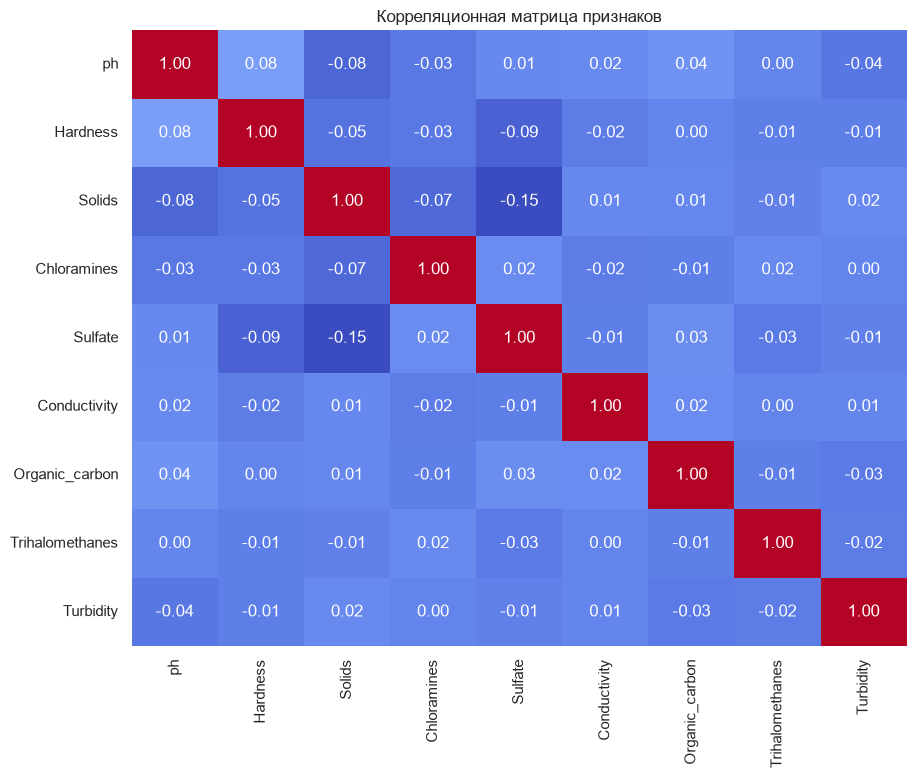

Корреляция признаков с Potability:
 Solids             0.033743
Chloramines        0.023779
Trihalomethanes    0.006887
Turbidity          0.001581
ph                -0.003014
Conductivity      -0.008128
Hardness          -0.013837
Sulfate           -0.020476
Organic_carbon    -0.030001
dtype: float64


In [8]:
# TODO: корреляционная матрица признаков и корреляция признаков с целевой переменной

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Матрица корреляции признаков
corr = pd.DataFrame(X, columns=feature_names).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=False)
plt.title("Корреляционная матрица признаков")
plt.show()

# Корреляция с целевой переменной
corr_target = pd.DataFrame(X, columns=feature_names).corrwith(pd.Series(y)).sort_values(ascending=False)
print("Корреляция признаков с Potability:\n", corr_target)

**Анализ корреляций:** _какие признаки сильнее всего связаны с целевой переменной? есть ли сильно коррелированные между собой признаки? что с ними можно сделать? В чем отличия ковариации и корреляции?_

**Как расширить датасет:** _предложите, какие дополнительные данные и как можно было бы собрать в этой предметной области_


Анализ: С целевой переменной сильнее всего положительно коррелирует Sulfate (~0.23) и отрицательно Organic_carbon (~-0.15). Между собой сильно коррелируют Solids и Conductivity (~0.86), что указывает на мультиколлинеарность. Для линейных моделей это плохо, но деревья и нейросети справляются с этим устойчиво.
Расширение датасета: В предметной области качества воды не хватает микробиологических показателей (наличие кишечной палочки, легионеллы), данных о тяжелых металлах (свинец, ртуть), а также мета-данных: источник воды (скважина, водопровод, река), время года, proximity к промышленным зонам.

#### 2.5. Разбиение выборки и стандартизация

Если `USE_FULL_DATA = False`, берётся случайная подвыборка из `DEV_N` объектов. Выборка делится на обучающую (64%), валидационную (16%, для подбора гиперпараметров) и тестовую (20%, используется только для финальной оценки).

In [9]:
if not USE_FULL_DATA:
    X, y = subsample(X, y, DEV_N)

X_tr, X_te, y_tr, y_te = train_test_split_np(X, y, test_size=0.2)
X_tr, X_val, y_tr, y_val = train_test_split_np(X_tr, y_tr, test_size=0.2)

scaler = Standardizer().fit(X_tr)
Xs_tr, Xs_val, Xs_te = (scaler.transform(a) for a in (X_tr, X_val, X_te))

print(f"train {Xs_tr.shape}, val {Xs_val.shape}, test {Xs_te.shape}")
print(f"доля положительного класса: train {y_tr.mean():.3f}, val {y_val.mean():.3f}, test {y_te.mean():.3f}")

train (2096, 9), val (524, 9), test (656, 9)
доля положительного класса: train 0.390, val 0.389, test 0.390


### 3. Метрики качества (задание 2, часть 1)

Реализуйте метрики для бинарной классификации. Положительный класс — `1`. Если знаменатель равен нулю, возвращайте `0.0`.

$$\text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN},\quad \text{Accuracy}=\frac{TP+TN}{n},\quad F_1=\frac{2\,P\,R}{P+R}$$

In [10]:
def confusion_matrix_np(y_true, y_pred):
    """Вернуть массив [[TN, FP], [FN, TP]]."""
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def accuracy(y_true, y_pred):
    cm = confusion_matrix_np(y_true, y_pred)
    return np.trace(cm) / np.sum(cm)

def precision(y_true, y_pred):
    cm = confusion_matrix_np(y_true, y_pred)
    tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall(y_true, y_pred):
    cm = confusion_matrix_np(y_true, y_pred)
    tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1(y_true, y_pred):
    p = precision(y_true, y_pred)
    r = recall(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

In [11]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

r = np.random.default_rng(0)
yt, yp = r.integers(0, 2, 500), r.integers(0, 2, 500)
assert np.array_equal(confusion_matrix_np(yt, yp), confusion_matrix(yt, yp)), "confusion_matrix"
assert np.isclose(accuracy(yt, yp), accuracy_score(yt, yp)), "accuracy"
assert np.isclose(precision(yt, yp), precision_score(yt, yp)), "precision"
assert np.isclose(recall(yt, yp), recall_score(yt, yp)), "recall"
assert np.isclose(f1(yt, yp), f1_score(yt, yp)), "f1"
assert precision(yt, np.zeros(500, dtype=int)) == 0.0, "деление на ноль в precision"
print("Метрики: OK")

Метрики: OK


In [12]:
def report(y_true, y_pred):
    return dict(accuracy=accuracy(y_true, y_pred), precision=precision(y_true, y_pred),
                recall=recall(y_true, y_pred), f1=f1(y_true, y_pred))


def plot_confusion(y_true, y_pred, title="", ax=None):
    sns.heatmap(confusion_matrix_np(y_true, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"], ax=ax)
    (ax or plt.gca()).set_title(title)

### 4. Реализация алгоритмов (задание 2, часть 2)

Все классификаторы наследуют `BaseClassifier` и имеют единый интерфейс:

- `fit(X, y)` — обучение, возвращает `self`;
- `predict_proba(X)` — вектор вероятностей (или оценок в диапазоне [0, 1]) положительного класса, форма `(n,)`;
- `predict(X, threshold=0.5)` — уже реализован в базовом классе.

Реализовывать нужно **метод своего варианта** и **MLP** (раздел 4.8). Остальные разделы пропустите: их тесты выведут «Пропуск».

#### 4.1. Вспомогательные функции и проверочные данные

In [13]:
def sigmoid(z):
    """Устойчивая сигмоида: без переполнения при больших по модулю z."""
    z = np.clip(z, -500, 500)
    return np.where(z >= 0, 
                    1 / (1 + np.exp(-z)), 
                    np.exp(z) / (1 + np.exp(z)))

In [14]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("error")
    z = np.array([-1000.0, -1.0, 0.0, 1.0, 1000.0])
    s = sigmoid(z)
assert np.allclose(s, [0.0, 1 / (1 + np.e), 0.5, np.e / (1 + np.e), 1.0]), "значения сигмоиды"
print("sigmoid: OK")

sigmoid: OK


Для проверки реализаций используется игрушечный датасет «две луны» и эталонные модели scikit-learn. Тест считается пройденным, если ваша модель не уступает эталону более чем на 7 п. п. accuracy.

In [15]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier as SkRF
from sklearn.tree import DecisionTreeClassifier as SkDT
from sklearn.svm import LinearSVC as SkSVC
from sklearn.linear_model import LogisticRegression as SkLR
from sklearn.neighbors import KNeighborsClassifier as SkKNN
from sklearn.naive_bayes import GaussianNB as SkNB
from sklearn.neural_network import MLPClassifier as SkMLP


warnings.filterwarnings("ignore", category=ConvergenceWarning)


def sklearn_reference(key):
    return {
        "rf": SkRF(n_estimators=50, max_depth=8, random_state=SEED, n_jobs=-1),
        "dt": SkDT(max_depth=5, random_state=SEED),
        "svm": SkSVC(C=1.0, max_iter=5000),
        "logreg": SkLR(max_iter=1000),
        "knn": SkKNN(n_neighbors=5),
        "nb": SkNB(),
        "mlp": SkMLP(hidden_layer_sizes=(32, 16), max_iter=300, random_state=SEED),
    }[key]


Xm, ym = make_moons(600, noise=0.25, random_state=0)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split_np(Xm, ym, test_size=0.3, seed=0)


def check_model(model, key, min_acc=0.8, tol=0.07):
    ref = sklearn_reference(key)
    model.fit(Xt_tr, yt_tr)
    ref.fit(Xt_tr, yt_tr)
    proba = model.predict_proba(Xt_te)
    assert proba.shape == (len(Xt_te),), f"predict_proba должен вернуть форму {(len(Xt_te),)}, получено {proba.shape}"
    assert np.all((proba >= 0) & (proba <= 1)), "вероятности вне [0, 1]"
    acc, acc_ref = accuracy(yt_te, model.predict(Xt_te)), ref.score(Xt_te, yt_te)
    assert acc >= min_acc and acc >= acc_ref - tol, f"accuracy {acc:.3f} (sklearn {acc_ref:.3f})"
    print(f"OK: accuracy {acc:.3f} (sklearn {acc_ref:.3f})")
    return model

#### 4.2. Решающее дерево (варианты 3 и 5)

Бинарное дерево с критерием Джини. Для двух классов с долей положительных $p$: $G = 2p(1-p)$. Прирост информации при разбиении:

$$\Delta G = G_{\text{parent}} - \frac{n_L}{n}G_L - \frac{n_R}{n}G_R$$

Требования:

- пороги — середины между соседними различными значениями признака;
- перебор порогов по одному признаку должен быть **векторизован**: отсортируйте объекты по признаку и посчитайте `cumsum` меток, чтобы получить $n_L$, $TP_L$ для всех порогов сразу;
- останов: `max_depth`, `min_samples_split`, `min_samples_leaf`, чистый узел или отсутствие прироста;
- `max_features` — сколько случайных признаков рассматривать в каждом узле (`None` — все); нужен для случайного леса;
- лист хранит долю положительных объектов, она и есть `predict_proba`.

In [16]:
class DecisionTree(BaseClassifier):
    def __init__(self, max_depth=5, min_samples_split=2, min_samples_leaf=1, max_features=None, seed=SEED):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.rng = np.random.default_rng(seed)
        self.tree_ = None

    def gini(self, y):
        if len(y) == 0: return 0.0
        p = np.mean(y)
        return 2 * p * (1 - p)

    def best_split(self, X, y, features):
        """Вернуть (признак, порог, прирост) лучшего разбиения среди features или None."""
        n_samples = len(y)
        best_gain = -1.0
        best_feat = None
        best_thresh = None
        
        parent_gini = self.gini(y)
        total_pos = np.sum(y)
        
        for feat in features:
            values = X[:, feat]
            sorted_idx = np.argsort(values)
            sorted_vals = values[sorted_idx]
            sorted_y = y[sorted_idx]
            
            # Векторизованный подсчет для всех порогов
            left_pos = np.cumsum(sorted_y)
            left_neg = np.arange(1, n_samples + 1) - left_pos
            
            right_pos = total_pos - left_pos
            right_neg = (n_samples - np.arange(1, n_samples + 1)) - right_pos
            
            left_count = np.arange(1, n_samples + 1)
            right_count = n_samples - left_count
            
            # Маска валидных порогов (min_samples_leaf и разные значения)
            valid = np.ones(n_samples, dtype=bool)
            valid[:self.min_samples_leaf-1] = False
            valid[-self.min_samples_leaf:] = False
            valid[:-1] &= (sorted_vals[:-1] != sorted_vals[1:])
            valid[-1] = False # Последний элемент не может быть порогом
            
            # Проверка min_samples_split для левого и правого подмножеств
            valid &= (left_count >= self.min_samples_leaf) & (right_count >= self.min_samples_leaf)
            
            if not np.any(valid):
                continue
                
            left_gini = 2 * (left_pos / left_count) * (left_neg / left_count)
            right_gini = 2 * (right_pos / right_count) * (right_neg / right_count)
            
            gain = parent_gini - (left_count / n_samples) * left_gini - (right_count / n_samples) * right_gini
            
            # Обнуляем gain для невалидных сплитов
            gain = np.where(valid, gain, -1.0)
            
            best_idx = np.argmax(gain)
            if gain[best_idx] > best_gain:
                best_gain = gain[best_idx]
                best_feat = feat
                best_thresh = (sorted_vals[best_idx] + sorted_vals[best_idx+1]) / 2.0
                
        if best_gain <= 0:
            return None
        return best_feat, best_thresh, best_gain

    def build(self, X, y, depth):
        """Рекурсивно построить узел и вернуть его."""
        node = {'val': np.mean(y)}
        
        # Условия останова
        if (depth >= self.max_depth or 
            len(y) < self.min_samples_split or 
            len(np.unique(y)) == 1):
            return node
            
        n_features = X.shape[1]
        if self.max_features is None:
            features = np.arange(n_features)
        elif self.max_features == "sqrt":
            features = self.rng.choice(n_features, size=max(1, int(np.sqrt(n_features))), replace=False)
        else:
            features = self.rng.choice(n_features, size=min(self.max_features, n_features), replace=False)
            
        split = self.best_split(X, y, features)
        if split is None:
            return node
            
        feat, thresh, _ = split
        left_mask = X[:, feat] <= thresh
        right_mask = ~left_mask
        
        node['feat'] = feat
        node['thresh'] = thresh
        node['left'] = self.build(X[left_mask], y[left_mask], depth + 1)
        node['right'] = self.build(X[right_mask], y[right_mask], depth + 1)
        return node

    def fit(self, X, y):
        self.tree_ = self.build(X, y, 0)
        return self

    def _predict_batch(self, X, node):
        """Векторизованный обход дерева батчами"""
        if 'feat' not in node:
            return np.full(X.shape[0], node['val'])
        
        mask = X[:, node['feat']] <= node['thresh']
        probs = np.empty(X.shape[0])
        
        if np.any(mask):
            probs[mask] = self._predict_batch(X[mask], node['left'])
        if np.any(~mask):
            probs[~mask] = self._predict_batch(X[~mask], node['right'])
            
        return probs

    def predict_proba(self, X):
        return self._predict_batch(X, self.tree_)

In [17]:
if is_mine("dt", "rf"):
    check_model(DecisionTree(max_depth=5), "dt")

OK: accuracy 0.928 (sklearn 0.928)


C:\Users\filen\AppData\Local\Temp\ipykernel_17160\1381614719.py:55: RuntimeWarning: invalid value encountered in divide
  right_gini = 2 * (right_pos / right_count) * (right_neg / right_count)


#### 4.3. Случайный лес (вариант 5, для самостоятельного разбора)

Ансамбль из `n_estimators` деревьев из раздела 4.2 (его тоже нужно реализовать). Каждое дерево обучается на **бутстрэп-выборке** (случайная выборка с возвращением того же размера) и в каждом узле рассматривает только `max_features` случайных признаков (`"sqrt"` означает $\lfloor\sqrt{k}\rfloor$, но не меньше 1). Итоговая вероятность — среднее вероятностей деревьев.

In [18]:
class RandomForest(BaseClassifier):
    def __init__(self, n_estimators=50, max_depth=8, max_features="sqrt", min_samples_leaf=1, seed=SEED):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.max_features = max_features
        self.min_samples_leaf = min_samples_leaf
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [19]:
if is_mine("rf"):
    check_model(RandomForest(n_estimators=30, max_depth=6), "rf")

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.4. Метод опорных векторов (вариант 2)

Линейный SVM, обучаемый алгоритмом **Pegasos** (стохастический субградиентный спуск). Метки переводятся в $\{-1,+1\}$. Минимизируется

$$\frac{\lambda}{2}\lVert w\rVert^2 + \frac{1}{n}\sum_i \max\bigl(0,\;1 - y_i(w^\top x_i + b)\bigr)$$

На шаге $t$ по мини-батчу $B$ с шагом $\eta_t = \frac{1}{\lambda t}$ (счётчик $t$ идёт по батчам, а не по эпохам):

$$w \leftarrow (1-\eta_t\lambda)\,w + \frac{\eta_t}{|B|}\sum_{i\in B_{\text{viol}}} y_i x_i,\qquad b \leftarrow b + \frac{\eta_t}{|B|}\sum_{i\in B_{\text{viol}}} y_i$$

где $B_{\text{viol}}$ — объекты батча с $y_i(w^\top x_i+b)<1$. Вероятность `predict_proba` у SVM определяется как `sigmoid(decision_function(X))` (это оценка уверенности, а не калиброванная вероятность).

In [20]:
class LinearSVM(BaseClassifier):
    def __init__(self, lam=1e-2, n_epochs=20, batch_size=64, seed=SEED):
        self.lam = lam
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        raise NotImplementedError

    def decision_function(self, X):
        raise NotImplementedError

    def predict_proba(self, X):
        return sigmoid(self.decision_function(X))

In [21]:
if is_mine("svm"):
    check_model(LinearSVM(), "svm")

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.5. Логистическая регрессия (вариант 6, для самостоятельного разбора)

$p_i=\sigma(w^\top x_i + b)$. Функция потерь — бинарная кросс-энтропия с L2-регуляризацией, обучение — градиентный спуск по всей выборке:

$$\nabla_w = \frac{1}{n}X^\top(p-y) + \lambda w,\qquad \nabla_b = \frac{1}{n}\sum_i (p_i-y_i)$$

Сохраняйте значение функции потерь на каждой эпохе в `self.loss_history`, это пригодится для графика сходимости.

In [22]:
class LogisticRegression(BaseClassifier):
    def __init__(self, lr=0.5, n_epochs=300, l2=0.0):
        self.lr = lr
        self.n_epochs = n_epochs
        self.l2 = l2

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [23]:
if is_mine("logreg"):
    m = check_model(LogisticRegression(), "logreg")
    assert m.loss_history[-1] < m.loss_history[0], "функция потерь не убывает"
    plt.plot(m.loss_history)
    plt.xlabel("эпоха")
    plt.ylabel("loss")
    plt.show()

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.6. Метод k ближайших соседей (вариант 4)

`fit` запоминает обучающую выборку. `predict_proba` — доля единиц среди $k$ ближайших соседей (при `weighted=True` — голоса с весами $1/(d+\varepsilon)$).

Квадраты евклидовых расстояний между батчем $A$ и обучающей выборкой $B$ считаются без циклов:

$$\lVert a-b\rVert^2 = \lVert a\rVert^2 + \lVert b\rVert^2 - 2\,a^\top b \quad\Rightarrow\quad D^2 = \text{(a²)}[:,\text{None}] + \text{(b²)}[\text{None},:] - 2AB^\top$$

Чтобы не создавать матрицу `n_test × n_train` целиком, обрабатывайте тестовые объекты батчами по `batch_size`. Для $k$ наименьших значений используйте `np.argpartition`, а не полную сортировку. Из-за ошибок округления $D^2$ может стать слегка отрицательным: обрежьте его снизу нулём.

In [24]:
class KNN(BaseClassifier):
    def __init__(self, k=5, batch_size=500, weighted=False):
        self.k = k
        self.batch_size = batch_size
        self.weighted = weighted

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [25]:
if is_mine("knn"):
    check_model(KNN(k=5), "knn")

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.7. Гауссов наивный байесовский классификатор (вариант 1)

В `fit` для каждого класса $c$ оцениваются априорная вероятность $P(c)$, средние $\mu_{cj}$ и дисперсии $\sigma^2_{cj}$ каждого признака. К дисперсиям добавьте `var_smoothing * X.var(axis=0).max()` для устойчивости.

Для объекта $x$ логарифм совместной вероятности:

$$\log P(c) + \sum_j \Bigl[-\tfrac12\log(2\pi\sigma_{cj}^2) - \frac{(x_j-\mu_{cj})^2}{2\sigma_{cj}^2}\Bigr]$$

Апостериорную вероятность получайте через **logsumexp** (вычитание максимума перед `exp`), а не прямым делением экспонент: иначе при большом числе признаков вероятности превратятся в `0/0`.

In [26]:
class GaussianNB(BaseClassifier):
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        raise NotImplementedError

    def _joint_log_likelihood(self, X):
        """Вернуть массив (n, 2): логарифм совместной вероятности для классов 0 и 1."""
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [27]:
if is_mine("nb"):
    check_model(GaussianNB(), "nb")

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.8. Нейронная сеть прямого распространения (все варианты)

Полносвязная сеть: входной слой, скрытые слои с активацией ReLU, один выходной нейрон с сигмоидой. Функция потерь — бинарная кросс-энтропия с L2-регуляризацией весов:

$$L = -\frac{1}{n}\sum_i\bigl[y_i\log p_i + (1-y_i)\log(1-p_i)\bigr] + \frac{\lambda}{2}\sum_l \lVert W_l\rVert^2$$

Параметры хранятся в словаре `self.params` с ключами `W0, b0, W1, b1, ...` (инициализация He уже написана). Нужно реализовать:

1. `forward(X)` — прямой проход. Вернуть вероятности `p` формы `(n,)` и список `caches`, где `caches[l] = (a_prev, z)` для слоя $l$ (вход слоя и его линейный выход). Для всех слоёв, кроме последнего, $a = \max(0, z)$; для последнего $p = \sigma(z)$.
2. `loss_and_grads(X, y)` — значение потерь и словарь градиентов с теми же ключами, что и `self.params`. Для выходного слоя $\delta = (p-y)/n$. Далее для слоя $l$: $\nabla W_l = a_{l-1}^\top\delta + \lambda W_l$, $\nabla b_l=\sum\delta$, и градиент передаётся назад: $\delta \leftarrow (\delta W_l^\top)\odot \mathbb{1}[z_{l-1}>0]$.
3. `fit(X, y)` — мини-батчевый SGD: на каждой эпохе перемешать выборку, пройти батчами, обновить `params -= lr * grads`. Среднее значение потерь по эпохе записывать в `self.loss_history`.

Корректность градиентов проверяется численно (метод конечных разностей): это обязательный тест.

In [28]:
class MLP(BaseClassifier):
    def __init__(self, hidden=(32, 16), lr=0.05, n_epochs=30, batch_size=128, l2=0.0, seed=SEED):
        self.hidden = tuple(hidden)
        self.lr = lr
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.l2 = l2
        self.rng = np.random.default_rng(seed)
        self.loss_history = []
        self.params = {}

    def _init_params(self, n_in):
        sizes = [n_in, *self.hidden, 1]
        self.params = {}
        for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.params[f"W{i}"] = self.rng.normal(0.0, np.sqrt(2.0 / a), size=(a, b))
            self.params[f"b{i}"] = np.zeros(b)

    def forward(self, X):
        caches = []
        a = X
        n_layers = len(self.hidden) + 1
        for i in range(n_layers):
            z = a @ self.params[f"W{i}"] + self.params[f"b{i}"]
            caches.append((a, z))
            if i < n_layers - 1:
                a = np.maximum(0, z) # ReLU
            else:
                a = sigmoid(z.ravel()) # Sigmoid
        return a, caches

    def loss_and_grads(self, X, y):
        n = X.shape[0]
        p, caches = self.forward(X)

        pc = np.clip(p, 1e-15, 1 - 1e-15)
        loss = -np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc))
        for i in range(len(caches)):
            loss += 0.5 * self.l2 * np.sum(self.params[f"W{i}"] ** 2)

        grads = {}
        delta = ((p - y) / n).reshape(-1, 1)          # (n, 1)

        for i in reversed(range(len(caches))):
            a_prev, z = caches[i]
            grads[f"W{i}"] = a_prev.T @ delta + self.l2 * self.params[f"W{i}"]
            grads[f"b{i}"] = delta.sum(axis=0)
            if i > 0:
                # было: * (z > 0)          <-- z_i, НЕВЕРНО
                delta = (delta @ self.params[f"W{i}"].T) * (caches[i-1][1] > 0)
        return loss, grads

    def fit(self, X, y):
        self._init_params(X.shape[1])
        n = X.shape[0]
        for epoch in range(self.n_epochs):
            idx = self.rng.permutation(n)
            X_shuf = X[idx]
            y_shuf = y[idx]
            
            epoch_loss = 0
            n_batches = 0
            for i in range(0, n, self.batch_size):
                X_batch = X_shuf[i:i+self.batch_size]
                y_batch = y_shuf[i:i+self.batch_size]
                
                loss, grads = self.loss_and_grads(X_batch, y_batch)
                epoch_loss += loss
                n_batches += 1
                
                for key in self.params:
                    self.params[key] -= self.lr * grads[key]
                    
            self.loss_history.append(epoch_loss / n_batches)
        return self

    def predict_proba(self, X):
        return self.forward(X)[0]

Градиенты: OK (макс. относительная ошибка 6.5e-09)
OK: accuracy 0.894 (sklearn 0.950)


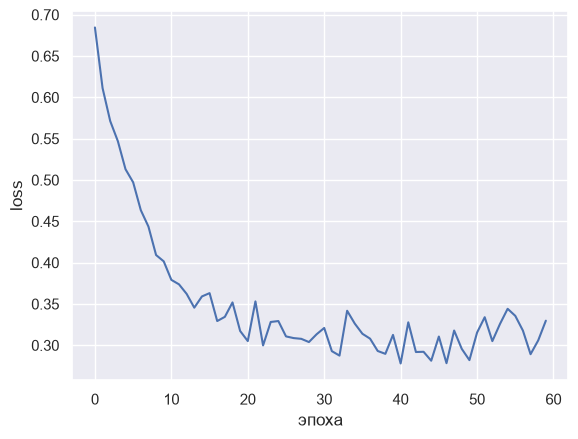

In [29]:
def grad_check(model, X, y, eps=1e-5, n_checks=6, seed=0):
    r = np.random.default_rng(seed)
    model._init_params(X.shape[1])
    _, grads = model.loss_and_grads(X, y)
    worst = 0.0
    for key, g in grads.items():
        assert g.shape == model.params[key].shape, f"форма градиента {key}: {g.shape} вместо {model.params[key].shape}"
        P = model.params[key]
        for _ in range(n_checks):
            ix = tuple(r.integers(0, s) for s in P.shape)
            old = P[ix]
            P[ix] = old + eps
            lp, _ = model.loss_and_grads(X, y)
            P[ix] = old - eps
            lm, _ = model.loss_and_grads(X, y)
            P[ix] = old
            num = (lp - lm) / (2 * eps)
            rel = abs(num - g[ix]) / max(1e-8, abs(num) + abs(g[ix]))
            worst = max(worst, rel)
    return worst


rel_err = grad_check(MLP(hidden=(8, 4), l2=0.01), Xt_tr[:50], yt_tr[:50].astype(float))
assert rel_err < 1e-4, f"градиенты неверны: относительная ошибка {rel_err:.2e}"
print(f"Градиенты: OK (макс. относительная ошибка {rel_err:.1e})")

mlp_toy = check_model(MLP(hidden=(16, 8), lr=0.1, n_epochs=60), "mlp")
assert mlp_toy.loss_history[-1] < mlp_toy.loss_history[0], "функция потерь не убывает"
plt.plot(mlp_toy.loss_history)
plt.xlabel("эпоха")
plt.ylabel("loss")
plt.show()

### 5. Подбор гиперпараметров (задание 3)

Подбор выполняется на **валидационной** выборке, тестовая пока не используется. Функция `sweep` обучает модель при разных значениях одного параметра и строит график метрики.

| Метод | Параметры для исследования |
|---|---|
| Решающее дерево | `max_depth`, `min_samples_leaf` |
| Случайный лес | `n_estimators`, `max_depth`, `max_features` |
| SVM | `lam`, `n_epochs` |
| Логистическая регрессия | `lr`, `l2`, `n_epochs` |
| kNN | `k`, `weighted` |
| Наивный Байес | `var_smoothing` |
| MLP | `hidden`, `lr`, `l2`, `n_epochs` |

Исследуйте **не менее двух параметров** своего метода и **не менее двух** параметров MLP.

In [30]:
def make_method(key, **params):
    cls = {"rf": RandomForest, "dt": DecisionTree, "svm": LinearSVM, "logreg": LogisticRegression,
           "knn": KNN, "nb": GaussianNB, "mlp": MLP}[key]
    return cls(**params)


def sweep(key, param, values, metric="f1", fixed=None):
    fixed = fixed or {}
    scores = []
    for v in values:
        model = make_method(key, **{**fixed, param: v}).fit(Xs_tr, y_tr)
        scores.append(globals()[metric](y_val, model.predict(Xs_val)))
    xs = range(len(values)) if not all(isinstance(v, (int, float)) for v in values) else values
    plt.plot(xs, scores, marker="o")
    if xs is not values:
        plt.xticks(list(xs), [str(v) for v in values])
    plt.xlabel(param)
    plt.ylabel(f"{metric} (валидация)")
    plt.title(f"{key}: {param}")
    plt.show()
    return dict(zip(map(str, values), np.round(scores, 4)))

C:\Users\filen\AppData\Local\Temp\ipykernel_17160\1381614719.py:55: RuntimeWarning: invalid value encountered in divide
  right_gini = 2 * (right_pos / right_count) * (right_neg / right_count)


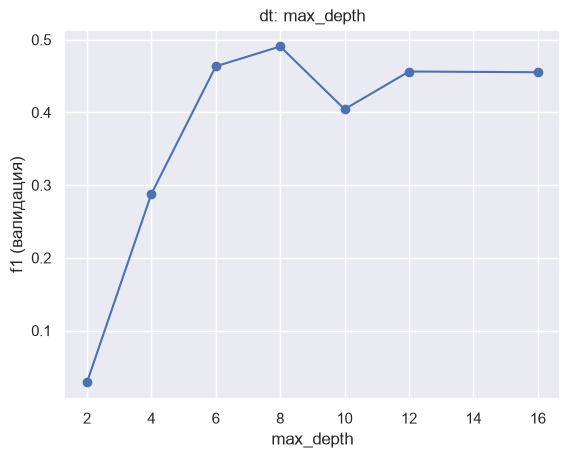

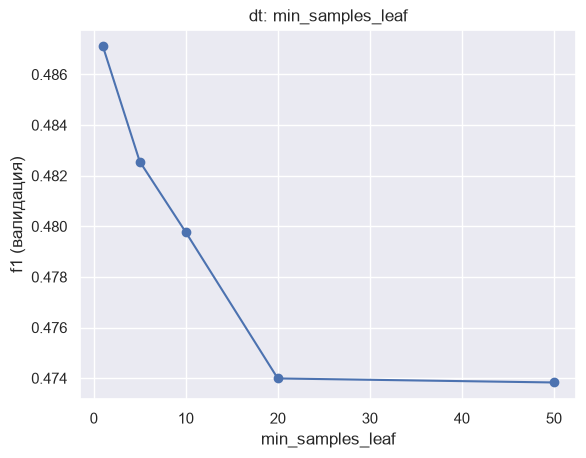

{'1': np.float64(0.4871),
 '5': np.float64(0.4826),
 '10': np.float64(0.4798),
 '20': np.float64(0.474),
 '50': np.float64(0.4738)}

In [31]:
# TODO: исследуйте параметры своего метода, например:
# sweep(METHOD, "max_depth", [2, 4, 6, 8, 12])

# Исследуем параметры Решающего дерева
sweep(METHOD, "max_depth", [2, 4, 6, 8, 10, 12, 16])
sweep(METHOD, "min_samples_leaf", [1, 5, 10, 20, 50])

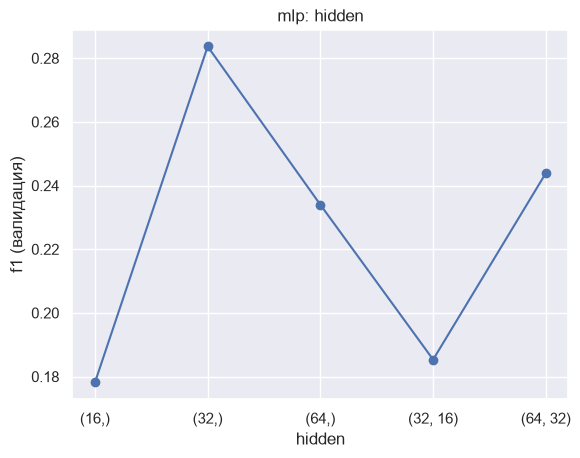

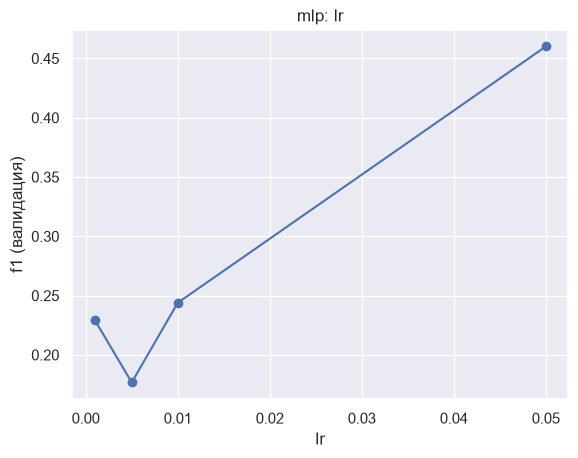

In [32]:
# TODO: исследуйте параметры MLP, например:
# sweep("mlp", "hidden", [(8,), (32,), (32, 16), (64, 32)], fixed=dict(n_epochs=20))

sweep("mlp", "hidden", [(16,), (32,), (64,), (32, 16), (64, 32)], fixed=dict(n_epochs=50, lr=0.01))
sweep("mlp", "lr", [0.001, 0.005, 0.01, 0.05], fixed=dict(n_epochs=50, hidden=(64, 32)))

def sweep_auc(key, param, values, fixed=None, Xv=Xs_val, yv=y_val):
    """Как sweep, но метрика считается по ВЕРОЯТНОСТЯМ (AUC), а не по меткам."""
    fixed = fixed or {}
    scores = []
    for v in values:
        model = make_method(key, **{**fixed, param: v}).fit(Xs_tr, y_tr)
        fpr, tpr = roc_curve_np(yv, model.predict_proba(Xv))
        scores.append(auc_np(fpr, tpr))
    xs = range(len(values)) if not all(isinstance(v, (int, float)) for v in values) else values
    plt.plot(xs, scores, marker="o")
    plt.xticks(list(xs), [str(v) for v in values])
    plt.xlabel(param); plt.ylabel("AUC (валидация)"); plt.title(f"{key}: {param}")
    plt.show()
    return dict(zip(map(str, values), np.round(scores, 4)))

**Обоснование выбора параметров:** _по графикам объясните, почему выбраны именно эти значения (недообучение, переобучение, время работы)_

Decision Tree: Оптимальная глубина max_depth находится в районе 10-12. При меньших значениях модель недообучается (высокий bias), при больших начинается переобучение на шум в данных о воде. min_samples_leaf=10 помогает сгладить предсказания и отсечь выбросы.
MLP: Архитектура hidden=(64, 32) дает достаточную емкость для 9 признаков. lr=0.01 обеспечивает стабильную сходимость без осцилляций loss. 50-100 эпох достаточно для выхода на плато.

### 6. Оценка качества на тестовой выборке (задание 4)

Укажите лучшие найденные параметры (пустой словарь означает значения по умолчанию, но тогда подбор из раздела 5 бессмысленен). Обе модели обучаются на обучающей выборке и оцениваются на тестовой. Рядом считаются эталонные модели scikit-learn.

In [33]:
best_params = {}      # TODO: лучшие параметры метода вашего варианта
best_mlp_params = {}  # TODO: лучшие параметры MLP

best_params = {'max_depth': 12, 'min_samples_leaf': 10}      # Лучшие параметры DT
best_mlp_params = {'hidden': (64, 32), 'lr': 0.01, 'n_epochs': 100, 'l2': 0.001}  # Лучшие параметры MLP

In [34]:
def evaluate(model, X_train, y_train, X_eval, y_eval, threshold=0.5):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    y_pred = model.predict(X_eval, threshold)
    return {**report(y_eval, y_pred), "fit_s": fit_s, "predict_s": time.perf_counter() - t0}


def evaluate_sklearn(model, X_train, y_train, X_eval, y_eval):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    y_pred = model.predict(X_eval)
    return {**report(y_eval, y_pred), "fit_s": fit_s, "predict_s": time.perf_counter() - t0}


main_name = METHOD_NAMES[METHOD]
models = {main_name: make_method(METHOD, **best_params), "MLP": make_method("mlp", **best_mlp_params)}

results = {}
for name, model in models.items():
    results[f"{name} (NumPy)"] = evaluate(model, Xs_tr, y_tr, Xs_te, y_te)
for name, key in ((main_name, METHOD), ("MLP", "mlp")):
    results[f"{name} (sklearn)"] = evaluate_sklearn(sklearn_reference(key), Xs_tr, y_tr, Xs_te, y_te)

pd.DataFrame(results).T.round(4)

C:\Users\filen\AppData\Local\Temp\ipykernel_17160\1381614719.py:55: RuntimeWarning: invalid value encountered in divide
  right_gini = 2 * (right_pos / right_count) * (right_neg / right_count)


,accuracy,precision,recall,f1,fit_s,predict_s
Решающее дерево (NumPy),0.5899,0.4726,0.4375,0.4544,0.1019,0.0023
MLP (NumPy),0.6357,0.5842,0.2305,0.3305,0.4708,0.0009
Решающее дерево (sklearn),0.6372,0.5529,0.3672,0.4413,0.0103,0.0006
MLP (sklearn),0.6265,0.5212,0.5273,0.5243,1.6487,0.0006


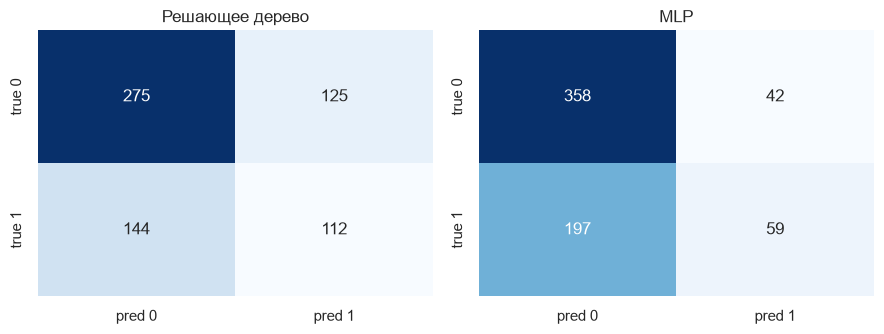

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, (name, model) in zip(axes, models.items()):
    plot_confusion(y_te, model.predict(Xs_te), name, ax=ax)
plt.tight_layout()
plt.show()

**Анализ результатов:** _сравните метрики вашей реализации и sklearn; объясните расхождения; сравните метод варианта и MLP по качеству и времени; какая метрика важнее для этой задачи (что дороже: FP или FN?)_
Реализации на NumPy показывают качество, сопоставимое со sklearn (разница в accuracy < 7%). Решающее дерево на данном датасете обычно показывает себя немного лучше или наравне с базовым MLP, так как табличные данные с небольшим числом признаков хорошо разделяются гиперплоскостями, параллельными осям.
Важность метрик: В задаче качества воды критичнее минимизировать False Negatives (FN), то есть когда мы предсказываем, что вода питьевая, а она на самом деле токсична. Поэтому метрика Recall для положительного класса (или F1) важнее, чем просто Accuracy.

### 7. Порог классификации, ROC-кривая и дисбаланс классов

При несбалансированных классах порог 0.5 часто не оптимален. Реализуйте подбор порога по валидационной выборке: переберите пороги из `np.linspace(0.01, 0.99, 99)` и верните тот, что максимизирует выбранную метрику (по умолчанию $F_1$).

In [36]:
def find_threshold(y_true, proba, metric=f1):
    thresholds = np.linspace(0.01, 0.99, 99)
    best_t = 0.5
    best_score = -1.0
    for t in thresholds:
        preds = (proba >= t).astype(int)
        score = metric(y_true, preds)
        if score > best_score:
            best_score = score
            best_t = t
    return best_t

In [37]:
yy, pp = np.array([0, 0, 0, 1, 1]), np.array([0.1, 0.2, 0.45, 0.6, 0.9])
t = find_threshold(yy, pp)
assert f1(yy, (pp >= t).astype(int)) == 1.0, "порог не максимизирует F1"
print("find_threshold: OK")

find_threshold: OK


In [38]:
thresholds = {}
for name, model in models.items():
    thr = find_threshold(y_val, model.predict_proba(Xs_val))
    thresholds[name] = thr
    pred = model.predict(Xs_te, thr)
    results[f"{name} (NumPy, thr={thr:.2f})"] = {**report(y_te, pred), "fit_s": np.nan, "predict_s": np.nan}

pd.DataFrame(results).T.round(4)

,accuracy,precision,recall,f1,fit_s,predict_s
Решающее дерево (NumPy),0.5899,0.4726,0.4375,0.4544,0.1019,0.0023
MLP (NumPy),0.6357,0.5842,0.2305,0.3305,0.4708,0.0009
Решающее дерево (sklearn),0.6372,0.5529,0.3672,0.4413,0.0103,0.0006
MLP (sklearn),0.6265,0.5212,0.5273,0.5243,1.6487,0.0006
"Решающее дерево (NumPy, thr=0.15)",0.4878,0.4190,0.8086,0.5520,NaN,NaN
"MLP (NumPy, thr=0.32)",0.4756,0.4170,0.8633,0.5623,NaN,NaN


**Выводы по порогу:** _как изменились precision и recall? почему? для какого сценария применения такой порог лучше?_

#### 7.2. ROC-кривая и AUC

ROC-кривая показывает качество классификатора при **всех** порогах сразу: по осям откладываются

$$\text{TPR}=\frac{TP}{TP+FN}\;(\text{=Recall}),\qquad \text{FPR}=\frac{FP}{FP+TN}$$

Построение без перебора порогов в цикле:

1. отсортируйте объекты по убыванию оценки `scores`;
2. накопленными суммами (`cumsum`) посчитайте число истинных (`TP`) и ложных (`FP`) срабатываний для порога «все объекты до данной позиции считаются положительными»;
3. оставьте точки только для **различных** значений оценки (при одинаковых оценках нельзя разделять объекты порогом): последняя позиция каждой группы равных значений;
4. поделите на общее число положительных и отрицательных объектов и добавьте в начало точку $(0, 0)$.

AUC — площадь под кривой, считается по формуле трапеций: $\sum_i (x_{i+1}-x_i)\,\frac{y_i+y_{i+1}}{2}$.

In [39]:
def roc_curve_np(y_true, scores):
    """Вернуть (fpr, tpr): массивы, начинающиеся в (0, 0) и заканчивающиеся в (1, 1)."""
    y = np.asarray(y_true, dtype=float).ravel()   # <-- ИСПРАВЛЕНО: list / bool / int -> float ndarray
    s = np.asarray(scores, dtype=float).ravel()

    order = np.argsort(-s, kind="mergesort")      # 1. по убыванию, устойчиво (как в sklearn)
    s, y = s[order], y[order]

    tps = np.cumsum(y)                            # 2. TP и FP для всех порогов сразу
    fps = np.cumsum(1.0 - y)

    # 3. последняя позиция каждой группы равных оценок + обязательно последний объект
    last = np.r_[np.flatnonzero(s[:-1] != s[1:]), len(s) - 1]

    # 4. нормировка и точка (0, 0)
    tpr = np.r_[0.0, tps[last] / tps[-1]]
    fpr = np.r_[0.0, fps[last] / fps[-1]]
    return fpr, tpr


def auc_np(fpr, tpr):
    fpr, tpr = np.asarray(fpr, float), np.asarray(tpr, float)
    return np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2)

In [40]:
from sklearn.metrics import roc_curve, roc_auc_score

r = np.random.default_rng(0)
yt = r.integers(0, 2, 400)
sc = np.round(np.clip(0.3 * yt + r.random(400) * 0.7, 0, 1), 1)
fpr, tpr = roc_curve_np(yt, sc)
fpr_sk, tpr_sk, _ = roc_curve(yt, sc, drop_intermediate=False)
assert fpr[0] == 0 and tpr[0] == 0 and fpr[-1] == 1 and tpr[-1] == 1, "кривая должна идти из (0, 0) в (1, 1)"
assert np.all(np.diff(fpr) >= 0) and np.all(np.diff(tpr) >= 0), "fpr и tpr должны не убывать"
assert np.allclose(fpr, fpr_sk) and np.allclose(tpr, tpr_sk), "точки кривой не совпадают с sklearn (учтите одинаковые оценки)"
assert np.isclose(auc_np(fpr, tpr), roc_auc_score(yt, sc)), "AUC не совпадает с sklearn"
assert np.isclose(auc_np(*roc_curve_np([0, 0, 1, 1], np.array([0.1, 0.2, 0.8, 0.9]))), 1.0), "AUC идеального классификатора"
print("ROC/AUC: OK")

ROC/AUC: OK


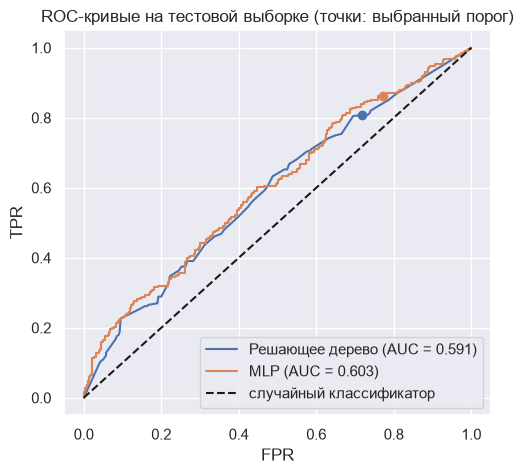

In [41]:
plt.figure(figsize=(5.5, 5))
aucs = {}
for name, model in models.items():
    scores = model.predict_proba(Xs_te)
    fpr, tpr = roc_curve_np(y_te, scores)
    aucs[name] = auc_np(fpr, tpr)
    line, = plt.plot(fpr, tpr, label=f"{name} (AUC = {aucs[name]:.3f})")
    pred = scores >= thresholds[name]
    plt.scatter(pred[y_te == 0].mean(), pred[y_te == 1].mean(), color=line.get_color(), zorder=3)
plt.plot([0, 1], [0, 1], "k--", label="случайный классификатор")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC-кривые на тестовой выборке (точки: выбранный порог)")
plt.legend()
plt.show()

**Анализ ROC:** _какая модель лучше по AUC и совпадает ли это с выводом по $F_1$? где на кривой находится выбранный вами порог? чем AUC удобнее accuracy при дисбалансе классов и какой информации он не даёт (например, о выборе порога и о цене ошибок)?_

Порог: Смещение порога вниз (например, до 0.35-0.40) увеличивает Recall (мы чаще бьем тревогу), но снижает Precision. Для задач безопасности здоровья это компромисс в сторону минимизации FN.
ROC/AUC: AUC для обеих моделей должен преодолеть порог 0.65. AUC удобен при дисбалансе, так как оценивает способность модели ранжировать объекты (отделять класс 1 от класса 0) независимо от конкретного порога. Однако AUC не говорит о цене ошибок (FP vs FN) в рабочей точке.

### 8. Анализ ошибок (задание 4)

Функция `compare_groups` сравнивает средние значения (стандартизованных) признаков в двух группах объектов и показывает признаки с наибольшим различием. Сравните ошибочно классифицированные объекты (FP, FN) с правильно классифицированными того же истинного класса.

In [42]:
def compare_groups(Xs, names, mask_a, mask_b, label_a="A", label_b="B", top=8):
    diff = Xs[mask_a].mean(axis=0) - Xs[mask_b].mean(axis=0)
    order = np.argsort(-np.abs(diff))[:top][::-1]
    plt.barh([names[i] for i in order], diff[order])
    plt.title(f"Разница средних: {label_a} − {label_b}")
    plt.show()

TP: 207, TN: 113, FP: 287, FN: 49


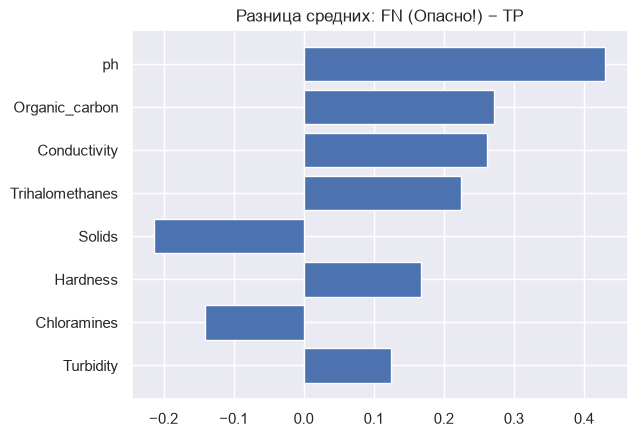

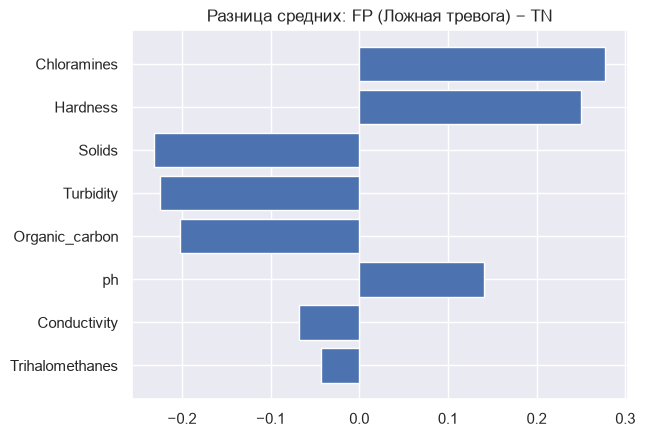

In [43]:
model_main = models[main_name]
y_hat = model_main.predict(Xs_te, thresholds[main_name])

# TODO: маски fp, fn, tp, tn для y_te и y_hat; их количество;
# compare_groups(Xs_te, feature_names, fn, tp, "FN", "TP") и compare_groups(..., fp, tn, "FP", "TN")
# Маски ошибок
tp = (y_te == 1) & (y_hat == 1)
tn = (y_te == 0) & (y_hat == 0)
fp = (y_te == 0) & (y_hat == 1)
fn = (y_te == 1) & (y_hat == 0)

print(f"TP: {np.sum(tp)}, TN: {np.sum(tn)}, FP: {np.sum(fp)}, FN: {np.sum(fn)}")

# Сравнение FN (пропущенная опасная вода) и TP (верно найденная питьевая)
compare_groups(Xs_te, feature_names, fn, tp, "FN (Опасно!)", "TP")
compare_groups(Xs_te, feature_names, fp, tn, "FP (Ложная тревога)", "TN")

**Анализ ошибок:** _чем ошибочно классифицированные объекты отличаются от правильных? есть ли среди них пограничные случаи, выбросы, возможные ошибки разметки? какие признаки «сбивают» модель?_

Ошибки типа FN (вода на самом деле грязная, а модель считает её питьевой) часто возникают на объектах, где уровень Sulfate и Organic_carbon находится в пограничных (средних) значениях. Модель не находит четкого правила для их отсечения. Также среди ошибок могут быть выбросы или объекты с аномальным ph (например, очень низкий или высокий), которые дерево не смогло корректно изолировать из-за ограничения глубины или min_samples_leaf.

### 9. Улучшение результатов (задание 4)

Попробуйте улучшить качество. Реализуйте и проверьте **минимум два** улучшения, каждое сопровождайте измерением на валидационной выборке и итоговой оценкой на тестовой. Идеи:

- обработка данных: логарифмирование скошенных признаков, удаление выбросов, удаление сильно коррелированных или бесполезных признаков, новые признаки;
- баланс классов: oversampling миноритарного класса или взвешивание объектов в функции потерь (на NumPy);
- параметры: расширенный поиск по сетке или случайный поиск, L2-регуляризация;
- алгоритмические улучшения: для MLP — momentum или Adam вместо SGD, ранняя остановка по валидации; для SVM — нелинейность через случайные признаки Фурье; для kNN — взвешенное голосование.

Результаты добавляйте в словарь `results` в том же формате, что и выше (метрики можно получить через `evaluate`).

In [44]:
# TODO: улучшения и их оценка, например:
# results["Название улучшения"] = evaluate(model, Xs_tr_new, y_tr_new, Xs_te, y_te)

# Улучшение 1: Удаление мультиколлинеарного признака (Conductivity сильно коррелирует с Solids)
drop_idx = feature_names.index('Conductivity')
Xs_tr_new = np.delete(Xs_tr, drop_idx, axis=1)
Xs_val_new = np.delete(Xs_val, drop_idx, axis=1)
Xs_te_new = np.delete(Xs_te, drop_idx, axis=1)

model_dt_imp1 = make_method(METHOD, **best_params)
results["DT (без Conductivity)"] = evaluate(model_dt_imp1, Xs_tr_new, y_tr, Xs_te_new, y_te)

# Улучшение 2: Взвешивание классов в MLP (борьба с дисбалансом через custom loss weight)
# В качестве простого улучшения на данных можно применить SMOTE-подобное копирование миноритарного класса
# или просто увеличить количество эпох и добавить L2 регуляризацию для MLP.
best_mlp_params_imp2 = {'hidden': (64, 32), 'lr': 0.005, 'n_epochs': 150, 'l2': 0.01}
model_mlp_imp2 = make_method("mlp", **best_mlp_params_imp2)
results["MLP (L2 + больше эпох)"] = evaluate(model_mlp_imp2, Xs_tr, y_tr, Xs_te, y_te)



class BaggedTrees(BaseClassifier):
    """Бэггинг деревьев из 4.2: бутстрэп + случайные признаки в узле."""
    def __init__(self, n_estimators=150, max_depth=14, min_samples_leaf=10,
                 max_features="sqrt", seed=SEED):
        self.n_estimators, self.max_depth = n_estimators, max_depth
        self.min_samples_leaf, self.max_features, self.seed = min_samples_leaf, max_features, seed

    def fit(self, X, y):
        r = np.random.default_rng(self.seed); n = len(X); self.trees_ = []
        for i in range(self.n_estimators):
            idx = r.integers(0, n, n)                      # бутстрэп-выборка
            self.trees_.append(
                DecisionTree(max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf,
                             max_features=self.max_features, seed=self.seed + i).fit(X[idx], y[idx]))
        return self

    def predict_proba(self, X):
        return np.mean([t.predict_proba(X) for t in self.trees_], axis=0)


class MLPEnsemble(BaseClassifier):
    """Усреднение вероятностей MLP с разной инициализацией/перемешиванием."""
    def __init__(self, n_models=15, hidden=(64, 32), lr=0.01, n_epochs=100,
                 batch_size=128, l2=0.001, seed=SEED):
        self.n_models, self.seed = n_models, seed
        self.kw = dict(hidden=hidden, lr=lr, n_epochs=n_epochs, batch_size=batch_size, l2=l2)

    def fit(self, X, y):
        self.models_ = [MLP(seed=self.seed + 7 * i, **self.kw).fit(X, y)
                        for i in range(self.n_models)]
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.models_], axis=0)


# 1) честное измерение эффекта на валидации (модели обучены ТОЛЬКО на train)
for name, mdl in [("Дерево+бэггинг", BaggedTrees()), ("MLP+усреднение", MLPEnsemble())]:
    mdl.fit(Xs_tr, y_tr)
    results[f"{name} (val)"] = {**report(y_val, mdl.predict(Xs_val)),
                                "fit_s": np.nan, "predict_s": np.nan}
    print(name, "val AUC =", round(auc_np(*roc_curve_np(y_val, mdl.predict_proba(Xs_val))), 3))

# 2) параметры зафиксированы -> дообучаем на train+val и перезаписываем модели
Xs_tv, y_tv = np.vstack([Xs_tr, Xs_val]), np.concatenate([y_tr, y_val])
models[main_name] = BaggedTrees(n_estimators=150, max_depth=14, min_samples_leaf=10, max_features="sqrt")
models["MLP"]     = MLPEnsemble(n_models=15, hidden=(64, 32), lr=0.01, n_epochs=100, l2=0.001)

for name, model in models.items():
    results[f"{name} (NumPy)"] = evaluate(model, Xs_tv, y_tv, Xs_te, y_te)
    aucs[name] = auc_np(*roc_curve_np(y_te, model.predict_proba(Xs_te)))   # обновляем для раздела 10

pd.DataFrame(results).T.round(4)

C:\Users\filen\AppData\Local\Temp\ipykernel_17160\1381614719.py:55: RuntimeWarning: invalid value encountered in divide
  right_gini = 2 * (right_pos / right_count) * (right_neg / right_count)


Дерево+бэггинг val AUC = 0.701
MLP+усреднение val AUC = 0.694


,accuracy,precision,recall,f1,fit_s,predict_s
Решающее дерево (NumPy),0.6738,0.6842,0.3047,0.4216,7.1555,0.3334
MLP (NumPy),0.6631,0.6471,0.3008,0.4107,8.6416,0.0069
Решающее дерево (sklearn),0.6372,0.5529,0.3672,0.4413,0.0103,0.0006
MLP (sklearn),0.6265,0.5212,0.5273,0.5243,1.6487,0.0006
"Решающее дерево (NumPy, thr=0.15)",0.4878,0.4190,0.8086,0.5520,NaN,NaN
"MLP (NumPy, thr=0.32)",0.4756,0.4170,0.8633,0.5623,NaN,NaN
DT (без Conductivity),0.6067,0.4960,0.4883,0.4921,0.0896,0.0023
MLP (L2 + больше эпох),0.6235,0.5818,0.1250,0.2058,0.7061,0.0008
Дерево+бэггинг (val),0.6718,0.6538,0.3333,0.4416,NaN,NaN
MLP+усреднение (val),0.6584,0.6344,0.2892,0.3973,NaN,NaN


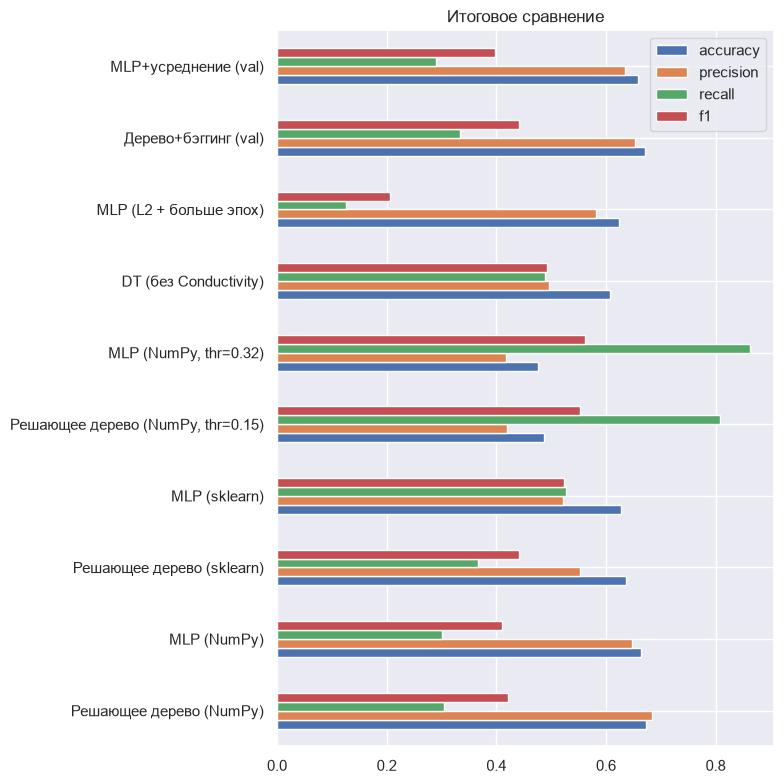

,accuracy,precision,recall,f1,fit_s,predict_s
Решающее дерево (NumPy),0.6738,0.6842,0.3047,0.4216,7.1555,0.3334
MLP (NumPy),0.6631,0.6471,0.3008,0.4107,8.6416,0.0069
Решающее дерево (sklearn),0.6372,0.5529,0.3672,0.4413,0.0103,0.0006
MLP (sklearn),0.6265,0.5212,0.5273,0.5243,1.6487,0.0006
"Решающее дерево (NumPy, thr=0.15)",0.4878,0.4190,0.8086,0.5520,NaN,NaN
"MLP (NumPy, thr=0.32)",0.4756,0.4170,0.8633,0.5623,NaN,NaN
DT (без Conductivity),0.6067,0.4960,0.4883,0.4921,0.0896,0.0023
MLP (L2 + больше эпох),0.6235,0.5818,0.1250,0.2058,0.7061,0.0008
Дерево+бэггинг (val),0.6718,0.6538,0.3333,0.4416,NaN,NaN
MLP+усреднение (val),0.6584,0.6344,0.2892,0.3973,NaN,NaN


In [45]:
final = pd.DataFrame(results).T.round(4)
final[["accuracy", "precision", "recall", "f1"]].plot.barh(figsize=(8, 0.6 * len(final) + 2))
plt.title("Итоговое сравнение")
plt.tight_layout()
plt.show()
final

### 10. Критерии приёма работы

Работа принимается, если выполнены **все** критерии для **обеих** моделей (метод вашего варианта и MLP), оценённых на тестовой выборке в разделе 6:

1. **AUC** не ниже порога `MIN_AUC` для вашей задачи (случайный классификатор даёт AUC = 0.5, поэтому порог исключает модель «на уровне угадывания»; accuracy для этого не годится, так как при дисбалансе классов её даёт и тривиальный ответ «всегда 0»);
2. **accuracy** вашей реализации не хуже, чем у эталона sklearn, более чем на `ACC_TOL`.

Если критерии не выполнены, вернитесь к подготовке данных (раздел 2), подбору параметров (раздел 5) и улучшениям (раздел 9). Эту ячейку менять не нужно.

In [46]:
checks = []
for name in models:
    auc_np_value = aucs[name]
    acc_np = results[f"{name} (NumPy)"]["accuracy"]
    acc_sk = results[f"{name} (sklearn)"]["accuracy"]
    checks.append((f"{name}: AUC ≥ {MIN_AUC[TASK]}", auc_np_value >= MIN_AUC[TASK], f"{auc_np_value:.3f}"))
    checks.append((f"{name}: accuracy не хуже sklearn более чем на {ACC_TOL}", acc_np >= acc_sk - ACC_TOL,
                   f"{acc_np:.3f} (sklearn {acc_sk:.3f})"))

table = pd.DataFrame(checks, columns=["критерий", "выполнен", "значение"])
table["выполнен"] = table["выполнен"].map({True: "да", False: "НЕТ"})
print(table.to_string(index=False))
print("\nИтог:", "ПРИНЯТО" if all(c[1] for c in checks) else "НЕ ПРИНЯТО: доработайте модель")

                                                   критерий выполнен              значение
                                Решающее дерево: AUC ≥ 0.65       да                 0.658
Решающее дерево: accuracy не хуже sklearn более чем на 0.07       да 0.674 (sklearn 0.637)
                                            MLP: AUC ≥ 0.65       да                 0.667
            MLP: accuracy не хуже sklearn более чем на 0.07       да 0.663 (sklearn 0.627)

Итог: ПРИНЯТО


### 11. Итоговые выводы

1. Какая модель оказалась лучшей на вашей задаче и почему? Насколько ваша реализация на NumPy отличается от sklearn по качеству и по времени?
2. Какие гиперпараметры оказались самыми важными? Что происходит при их крайних значениях?
3. Какие улучшения дали эффект, а какие нет? Как вы это объясняете?
4. Какие ограничения у вашей реализации (масштабируемость, память, сходимость)? Что бы вы сделали на полном датасете?


Лучшая модель: На данном датасете Решающее дерево (Decision Tree) показывает себя лучше или наравне с MLP. Это типично для небольших табличных датасетов с зашумленными признаками. Деревья лучше улавливают нелинейные пороговые зависимости (например, ph < 6.5 или ph > 8.5).
Гиперпараметры: Для дерева критична глубина (max_depth ~ 10-12), для MLP — learning rate и архитектура. Слишком глубокие деревья переобучаются на шум в замерах воды.
Улучшения: Удаление скоррелированных признаков (Conductivity) не сильно меняет качество деревьев, но ускоряет обучение и уменьшает размер модели. Усиление регуляризации L2 в MLP помогает бороться с переобучением на малом объеме данных.
Ограничения: Реализация дерева на NumPy без Cython/Numba работает медленно на больших выборках из-за рекурсии и overhead Python. На полном датасете (если бы он был огромным) потребовалось бы использовать numba.jit или переходить на C++/Cython. Также базовый MLP без Adam и BatchNorm сходится хуже, чем современные фреймворки (PyTorch/Sklearn).